<div style="text-align:left;">
    <span style="color:red; font-size:28px; font-weight:bold;">
        Project Part 2
    </span>
</div>

<div style="text-align:left;">
    <span style="color: blue; font-size:22px; font-weight:bold;">
        Lets integrate Temperature and weather Inputs
    </span>
</div>

<div style="text-align:left;">
    <span style="color: green; font-size:16px; font-weight:bold;">
        Data were obtain by running a direct code in Python
    </span>
</div>

In [1]:
import requests
import pandas as pd

cities = {
    "Berlin": (52.52, 13.41),
    "Hamburg": (53.55, 10.00),
    "Munich": (48.14, 11.58),
    "Cologne": (50.94, 6.96),
    "Frankfurt": (50.11, 8.68),
    "Leipzig": (51.34, 12.37),
    "Stuttgart": (48.78, 9.18),
    "Bremen": (53.08, 8.80)
}

start_date = "2015-01-01"
end_date = "2026-06-30"

dfs = []

for city, (lat, lon) in cities.items():
    url = (
        "https://archive-api.open-meteo.com/v1/archive"
        f"?latitude={lat}"
        f"&longitude={lon}"
        f"&start_date={start_date}"
        f"&end_date={end_date}"
        "&daily=temperature_2m_mean"
        "&timezone=Europe/Berlin"
    )

    response = requests.get(url)
    response.raise_for_status()

    data = response.json()["daily"]

    df = pd.DataFrame({
        "date": data["time"],
        city: data["temperature_2m_mean"]
    })

    dfs.append(df)


result = dfs[0]
for df in dfs[1:]:
    result = result.merge(df, on="date")

result["Germany_avg_temp"] = result.iloc[:, 1:].mean(axis=1)

##### Presentation of the average temperature by month in Germany from January 2015
##### To June 2026

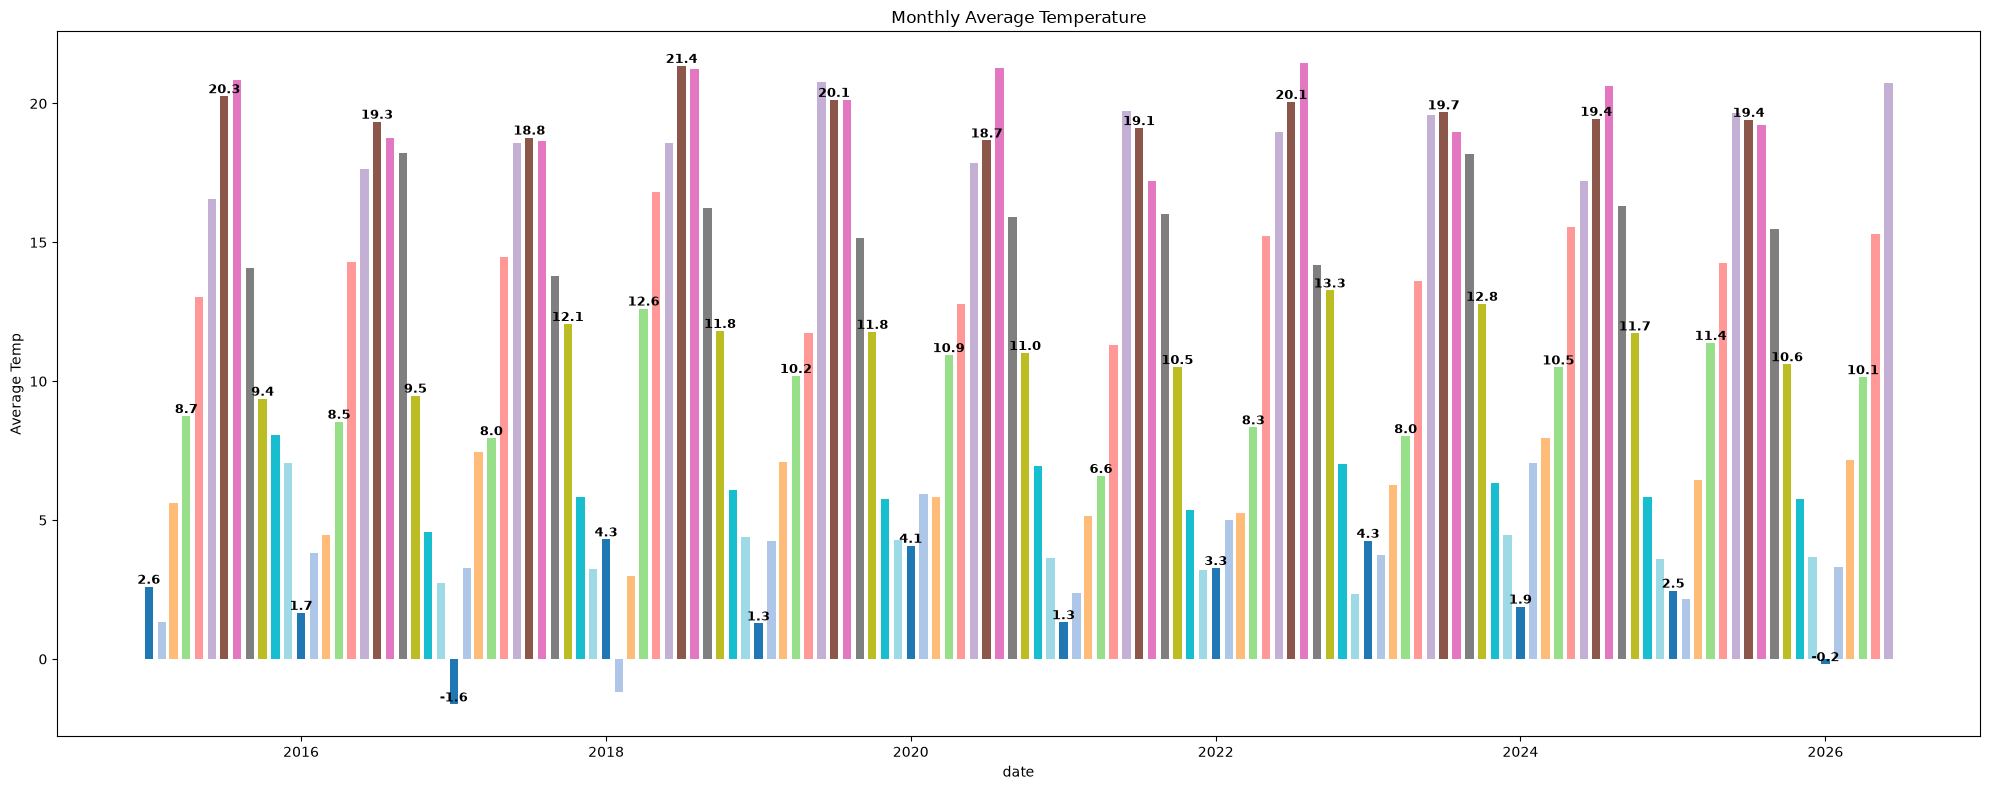

In [2]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt

result["Germany_avg_temp"]=result["Germany_avg_temp"].round(1)

result["date"]= pd.to_datetime(result["date"])

monthly = (
    result.groupby(pd.Grouper(key="date", freq="MS"))["Germany_avg_temp"]
    .mean()
    .reset_index()
)
month_colors = plt.colormaps["tab20"].resampled(12)
colors =[month_colors(d.month - 1) for d in monthly["date"]]
plt.figure(figsize=(20,8))
bars = plt.bar(monthly["date"], monthly["Germany_avg_temp"], width=20, color=colors)
label_months = {1,4,7,10}
for bar, d, val in zip(bars, monthly["date"], monthly["Germany_avg_temp"]):
    if d.month in label_months:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{val:.1f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )
plt.xlabel("date")
plt.ylabel("Average Temp")
plt.title("Monthly Average Temperature")
plt.tight_layout()
plt.show()

##### recent April-June are warmer than before 2018

<div style="text-align:left;">
    <span style="color: blue; font-size:22px; font-weight:bold;">
        Lets import the Production index
    </span>
</div>

<div style="text-align:left;">
    <span style="color: green; font-size:16px; font-weight:bold;">
        Data were obtained from Eurostat
    </span>
</div>

In [3]:
Index_Production= pd.read_csv("/Users/jeanmiccheltia/Downloads/Production Index.csv", sep=";", header=0)
Index_Production["TIME"] = pd.to_datetime(Index_Production["TIME"], format="%d.%m.%y")
Index_Production["Germany"] =(Index_Production["Germany"]
                .astype(str)
                .str.strip()
                .str.replace(".","",regex=False)
                .str.replace(",",".",regex=False)
               )

Index_Production["Germany"]= pd.to_numeric(Index_Production["Germany"], errors="coerce")

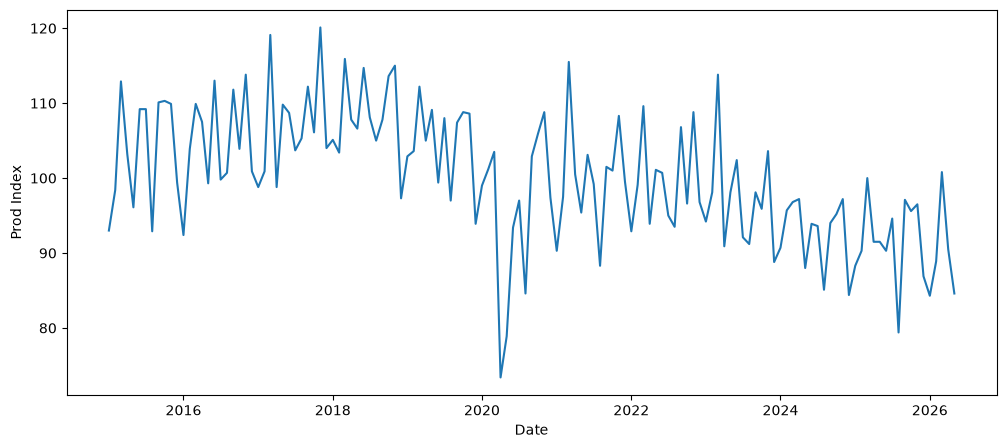

In [4]:
plt.figure(figsize=(12,5))
plt.plot(Index_Production["TIME"], Index_Production["Germany"])
plt.xlabel("Date")
plt.ylabel("Prod Index")
plt.show()

##### Slight rebound after Covid and down since 2023. Lets appearing the same trend with Grid load or Electricity consumption in Germany

<div style="text-align:left;">
    <span style="color: purple; font-size:14px; font-weight:bold;">
        lets have a comparision of the trend with the trend of the electricity consumption
    </span>
</div>

<div style="text-align:left;">
    <span style="color: blue; font-size:22px; font-weight:bold;">
        Lets import the electricity Consumption
    </span>
</div>

In [5]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error


Production  = pd.read_csv("/Users/jeanmiccheltia/Documents/Electricity Germany Data.csv", sep=";", header=0)
Production = Production.rename(columns={
              "Datum von": "date",
              "Datum bis": "Date to",
              "Biomasse [MWh] Berechnete Auflösungen": "Biomass [MWh]",
              "Wasserkraft [MWh] Berechnete Auflösungen": "Hydropower [MWh]",
              "Wind Offshore [MWh] Berechnete Auflösungen":	"Offshore Wind [MWh]",
              "Wind Onshore [MWh] Berechnete Auflösungen": "Onshore Wind [MWh]",
              "Photovoltaik [MWh] Berechnete Auflösungen":"Photovoltaics [MWh]",
              "Sonstige Erneuerbare [MWh] Berechnete Auflösungen":"Other renewables [MWh]",
              "Kernenergie [MWh] Berechnete Auflösungen":"Nuclear energy [MWh]",
              "Braunkohle [MWh] Berechnete Auflösungen":"Lignite [MWh]",
              "Steinkohle [MWh] Berechnete Auflösungen": "Hard coal [MWh]",
              "Erdgas [MWh] Berechnete Auflösungen": "Natural gas [MWh]",
              "Pumpspeicher [MWh] Berechnete Auflösungen":"Pumped-storage [MWh]",
              "Sonstige Konventionelle [MWh] Berechnete Auflösungen": "Other Conventional [MWh]",
              "Netzlast [MWh] Berechnete Auflösungen": "Grid load [MWh]"
})
cols = Production.columns.drop("date")
Production["date"]=pd.to_datetime(Production["date"], format="%d.%m.%y")
Production[cols] = (
    Production[cols]
    .replace({r"\.": "", ",": "."}, regex=True)
    .apply(pd.to_numeric, errors="coerce")
)
Production["Other renewables [MWh]"] = Production["Other renewables [MWh]"].ffill()
Production["Pumped-storage [MWh]"] = Production["Pumped-storage [MWh]"].ffill()

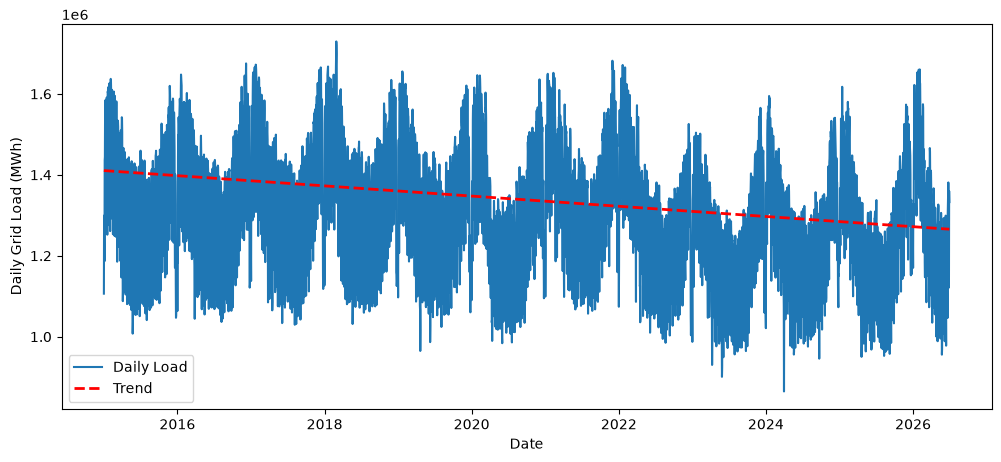

In [6]:
daily_consumption = (
    Production.groupby(Production["date"].dt.date)["Grid load [MWh]"]
              .sum()
)

x = np.arange(len(daily_consumption))
y = daily_consumption.values

z = np.polyfit(x, y, 1)
trend = np.poly1d(z)

plt.figure(figsize=(12, 5))
plt.plot(daily_consumption.index, y, label="Daily Load")
plt.plot(daily_consumption.index, trend(x), 'r--', linewidth=2, label="Trend")

plt.xlabel("Date")
plt.ylabel("Daily Grid Load (MWh)")
plt.legend()
plt.show()

##### We note the down trend from 2022, a plot on the same graph will show trend for Industry productio index
##### and electricity consumption

<div style="text-align:left;">
    <span style="color: blue; font-size:22px; font-weight:bold;">
        Lets merge the 3 dataset for analysis and for the Model
    </span>
</div>

In [7]:
merged = Production.merge(
    result,
    on="date",
    how="left",
    indicator=True
)

print(merged["_merge"].value_counts())

_merge
both          4199
left_only        0
right_only       0
Name: count, dtype: int64


<Axes: >

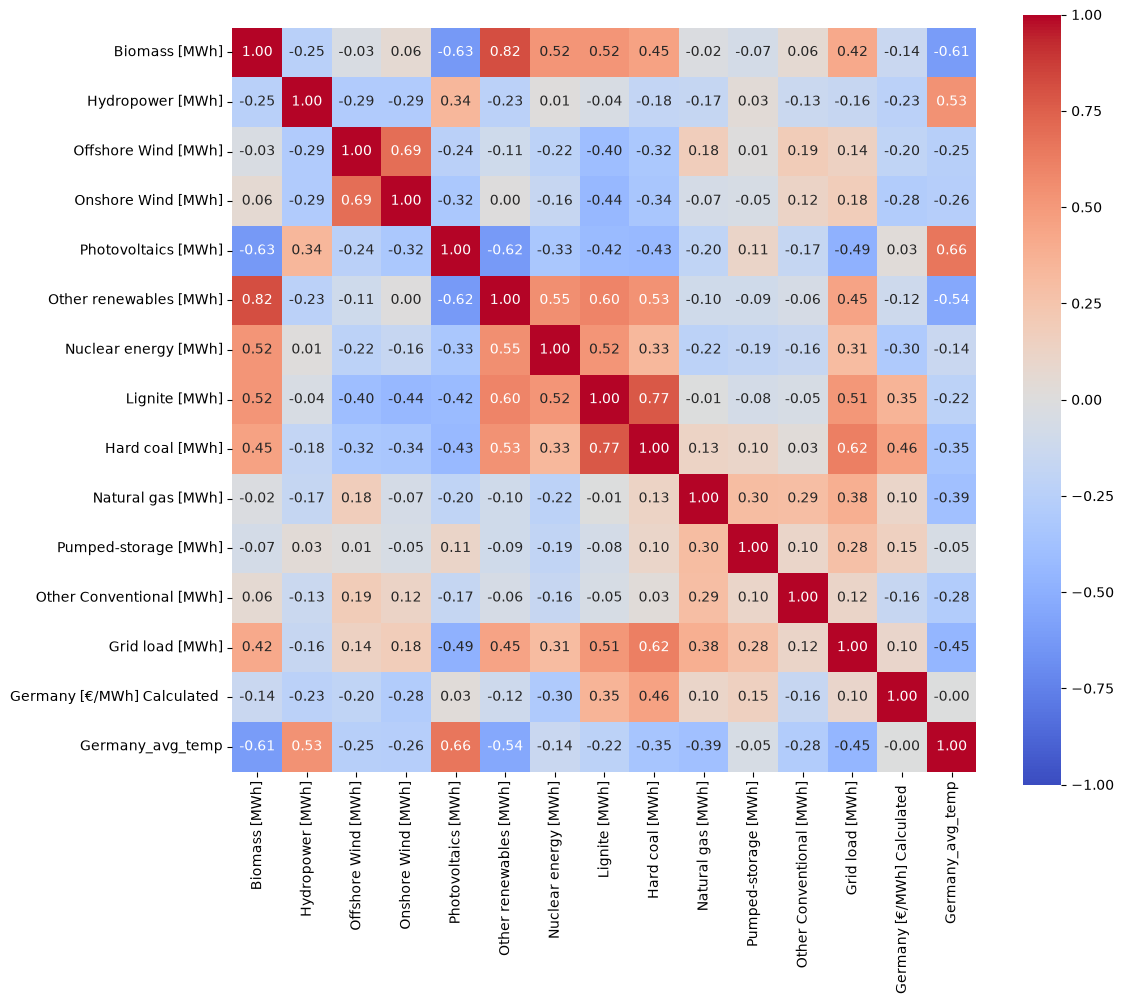

In [8]:
import seaborn as sns

merged = merged.drop(columns=['Berlin', 'Hamburg', 'Munich', 'Cologne', 'Frankfurt', 'Leipzig', 'Stuttgart', 'Bremen'])

corr = merged.select_dtypes(include="float").corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    annot=True,      
    cmap="coolwarm", 
    vmin=-1,
    vmax=1,
    square=True,
    fmt=".2f"
)

In [9]:
from statsmodels.tsa.seasonal import seasonal_decompose

Index_Production = Index_Production.rename(columns={
              "TIME": "date","Germany":"prod_index"})
monthly_prod = Index_Production.set_index("date")["prod_index"].asfreq("MS")

decomp = seasonal_decompose(monthly_prod, model="additive", period=12)

Index_Production = Index_Production.set_index("date")
Index_Production["production_deseasonalized"] = decomp.trend + decomp.resid
Index_Production = Index_Production.reset_index()

Index_Production["month"] = Index_Production["date"].dt.to_period("M")
merged["month"] = merged["date"].dt.to_period("M")

merged = merged.drop(columns=["production_deseasonalized"], errors="ignore")  # clear any prior bad merge

merged = merged.merge(
    Index_Production[["month", "production_deseasonalized","prod_index"]],
    on="month",
    how="left"
)

In [10]:
merged["production_deseasonalized"] = merged["production_deseasonalized"].bfill().ffill()
print(merged["production_deseasonalized"].isna().sum())  
runs = merged["production_deseasonalized"].ne(merged["production_deseasonalized"].shift()).cumsum()

0


##### Lets check the merged 

In [11]:
runs = merged["production_deseasonalized"].ne(merged["production_deseasonalized"].shift()).cumsum()
run_sizes = merged.groupby(runs).size()
longest_run_id = run_sizes.idxmax()
print(merged[runs == longest_run_id]["date"].agg(["min", "max"]))

min   2025-11-01
max   2026-06-30
Name: date, dtype: datetime64[ns]


##### Lets integrate the national holidays during the period

In [12]:
merged["day_of_week"] = merged["date"].dt.dayofweek
merged["is_weekend"] = merged["day_of_week"].isin([5,6]).astype(int)

import holidays

Germany_holidays = holidays.Germany(years=range(2015,2027))
merged["is_holiday"]= merged["date"].isin(Germany_holidays).astype(int)

dow_dummies = pd.get_dummies(merged["day_of_week"], prefix="dow", drop_first=True)
merged = pd.concat([merged, dow_dummies], axis=1)

/var/folders/np/v9js13r17k9_qp03z_bwglkh0000gn/T/ipykernel_8593/2022983347.py:7: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  merged["is_holiday"]= merged["date"].isin(Germany_holidays).astype(int)


<div style="text-align:left;">
    <span style="color: purple; font-size:14px; font-weight:bold;">
        lets integrate the weather sensitivity
    </span>
</div>

##### we select cooling base as 20.0 and heating base at 15.0 degree celcius

In [17]:
base_heating = 15.0
base_cooling = 20.0

merged["HDD"] = (base_heating - merged["Germany_avg_temp"]).clip(lower=0)
merged["CDD"] = (merged["Germany_avg_temp"] - base_cooling).clip(lower=0)

for lag in [1,2,3]:
    merged[f"HDD_lag{lag}"] = merged["HDD"].shift(lag)
    merged[f"CDD_lag{lag}"] = merged["CDD"].shift(lag)
merged["HDD_roll3"]= merged["HDD"].rolling(window=3).mean()
merged["CDD_roll3"]= merged["CDD"].rolling(window=3).mean()

merged["HDD_roll7"]= merged["HDD"].rolling(window=7).mean()
merged["CDD_roll7"]= merged["CDD"].rolling(window=7).mean()

In [20]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

candidate_vars = [
    "HDD_roll3", "CDD_roll3", "HDD_roll7", "CDD_roll7",
    "HDD", "CDD", "is_weekend", "is_holiday",
    "Germany_avg_temp", "prod_index","day_of_week","production_deseasonalized"
]

X = merged[candidate_vars].dropna().astype(float)

vif_data = pd.DataFrame()

vif_data["variable"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.sort_values(by="VIF", ascending=False)) 

                     variable         VIF
11  production_deseasonalized  472.959817
9                  prod_index  359.801570
0                   HDD_roll3  105.262546
4                         HDD   71.644159
8            Germany_avg_temp   58.945481
2                   HDD_roll7   40.323842
1                   CDD_roll3    8.774302
10                day_of_week    8.627891
5                         CDD    5.084177
3                   CDD_roll7    4.667323
6                  is_weekend    3.732245
7                  is_holiday    1.038162


##### Production deseasonalized and production being correlated, one may have to be dropped , similar there are great colinearity between the HDD

##### excludes: HDD, HDD_roll7, CDD, Germany_avg_temp (redundant with HDD family), Prod_index (raw, redundant with production_deseasonalized), day_of_week (redundant with is_weekend)

In [22]:
final_vars = ["HDD_roll3", "CDD_roll3","CDD_roll7", "production_deseasonalized", "is_weekend", "is_holiday"]


X = merged[final_vars].dropna().astype(float)

vif_data = pd.DataFrame()
vif_data["variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data.sort_values("VIF", ascending=False))

                    variable       VIF
2                  CDD_roll7  4.876876
1                  CDD_roll3  4.625709
3  production_deseasonalized  2.992514
0                  HDD_roll3  2.309934
4                 is_weekend  1.398547
5                 is_holiday  1.030114


<div style="text-align:left;">
    <span style="color: red; font-size:14px; font-weight:bold;">
        lets implement the first Model a Arima Model since the series are known to be stationary
    </span>
</div>

In [23]:
import statsmodels.api as sm

dow_dummies = pd.get_dummies(merged["day_of_week"], prefix="dow", drop_first=True)

X = pd.concat([merged[final_vars], dow_dummies], axis=1)
X = sm.add_constant(X.astype(float))
y = merged["Grid load [MWh]"]

valid = X.notna().all(axis=1) & y.notna()
model = sm.OLS(y[valid], X[valid]).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        Grid load [MWh]   R-squared:                       0.831
Model:                            OLS   Adj. R-squared:                  0.831
Method:                 Least Squares   F-statistic:                     1868.
Date:                Mon, 20 Jul 2026   Prob (F-statistic):               0.00
Time:                        14:06:45   Log-Likelihood:                -52577.
No. Observations:                4193   AIC:                         1.052e+05
Df Residuals:                    4181   BIC:                         1.053e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [28]:
dow_dummies = pd.get_dummies(merged["day_of_week"], prefix="dow", drop_first=True)

exog_vars = pd.concat([
    merged[["HDD_roll3", "CDD_roll3","CDD_roll7", "production_deseasonalized", "is_holiday","is_weekend"]],
    dow_dummies
], axis=1)

y = merged["Grid load [MWh]"]

valid = exog_vars.notna().all(axis=1) & y.notna()
y_valid = y[valid].reset_index(drop=True)
exog_valid = exog_vars[valid].astype(float).reset_index(drop=True)
merged_dates = merged.loc[valid, "date"].reset_index(drop=True)

test_size = 840

y_train, y_test = y_valid.iloc[:-test_size], y_valid.iloc[-test_size:]
exog_train, exog_test = exog_valid.iloc[:-test_size], exog_valid.iloc[-test_size:]

from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    y_train,
    exog=exog_train,
    order=(3,0,2),
    seasonal_order=(1,0,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
)
fit = model.fit(disp=False)
print(fit.summary())

/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                                      SARIMAX Results                                      
Dep. Variable:                     Grid load [MWh]   No. Observations:                 3353
Model:             SARIMAX(3, 0, 2)x(1, 0, [1], 7)   Log Likelihood              -40582.746
Date:                             Mon, 20 Jul 2026   AIC                          81205.492
Time:                                     14:17:01   BIC                          81327.785
Sample:                                          0   HQIC                         81249.239
                                            - 3353                                         
Covariance Type:                               opg                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
HDD_roll3                  1.468e+04    731.819     20.066      0.000    1.3

In [29]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

forecast = fit.forecast(steps=test_size, exog=exog_test)
mape = mean_absolute_percentage_error(y_test, forecast)
rmse = np.sqrt(mean_squared_error(y_test, forecast))
print(f"MAPE: {mape:.2%}, RMSE: {rmse:.2f}")

MAPE: 6.10%, RMSE: 99128.56


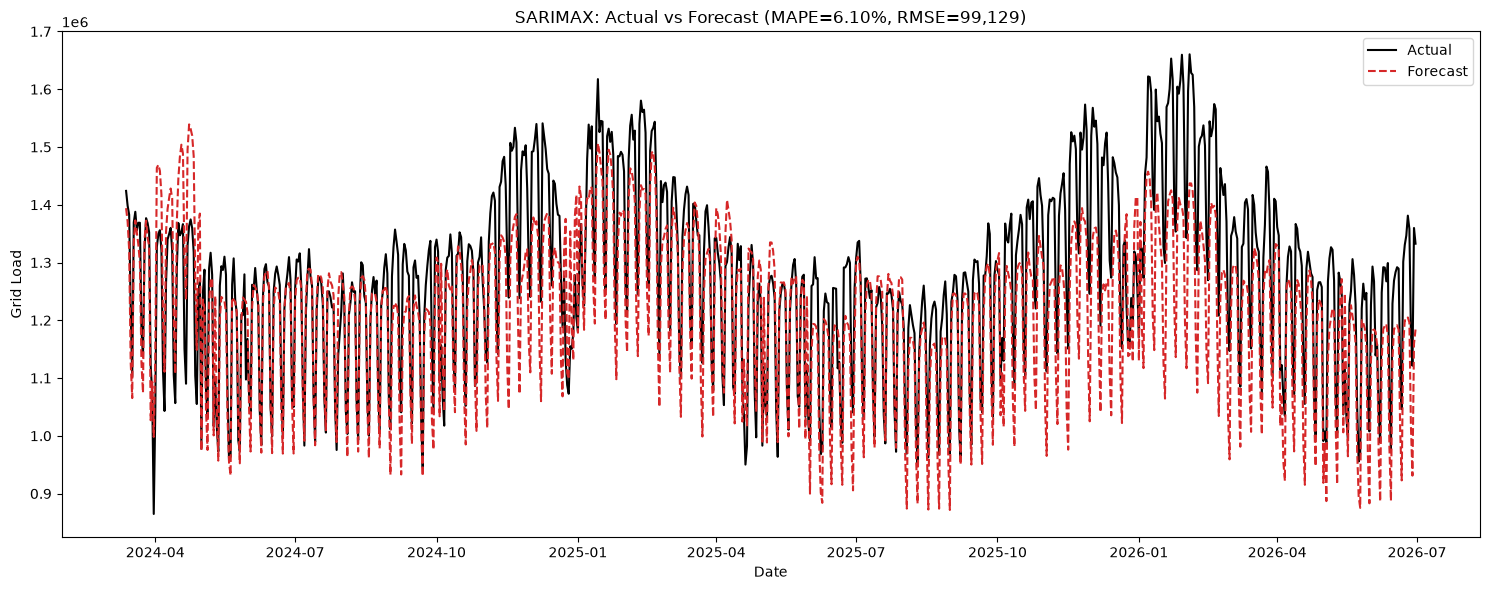

In [31]:
test_dates = merged_dates.iloc[-test_size:]

plt.figure(figsize=(15, 6))
plt.plot(test_dates, y_test.values, label="Actual", color="black", linewidth=1.5)
plt.plot(test_dates, forecast.values, label="Forecast", color="tab:red", linestyle="--", linewidth=1.5)
plt.xlabel("Date")
plt.ylabel("Grid Load")
plt.title(f"SARIMAX: Actual vs Forecast (MAPE={mape:.2%}, RMSE={rmse:,.0f})")
plt.legend()
plt.tight_layout()
plt.show()

##### 6.1% MAPE how well the Arima model explain load given perfect knowledge of temperature and production, rather than "how well we could have actually forecast load 840 days ago with a MAPE of 9.4%

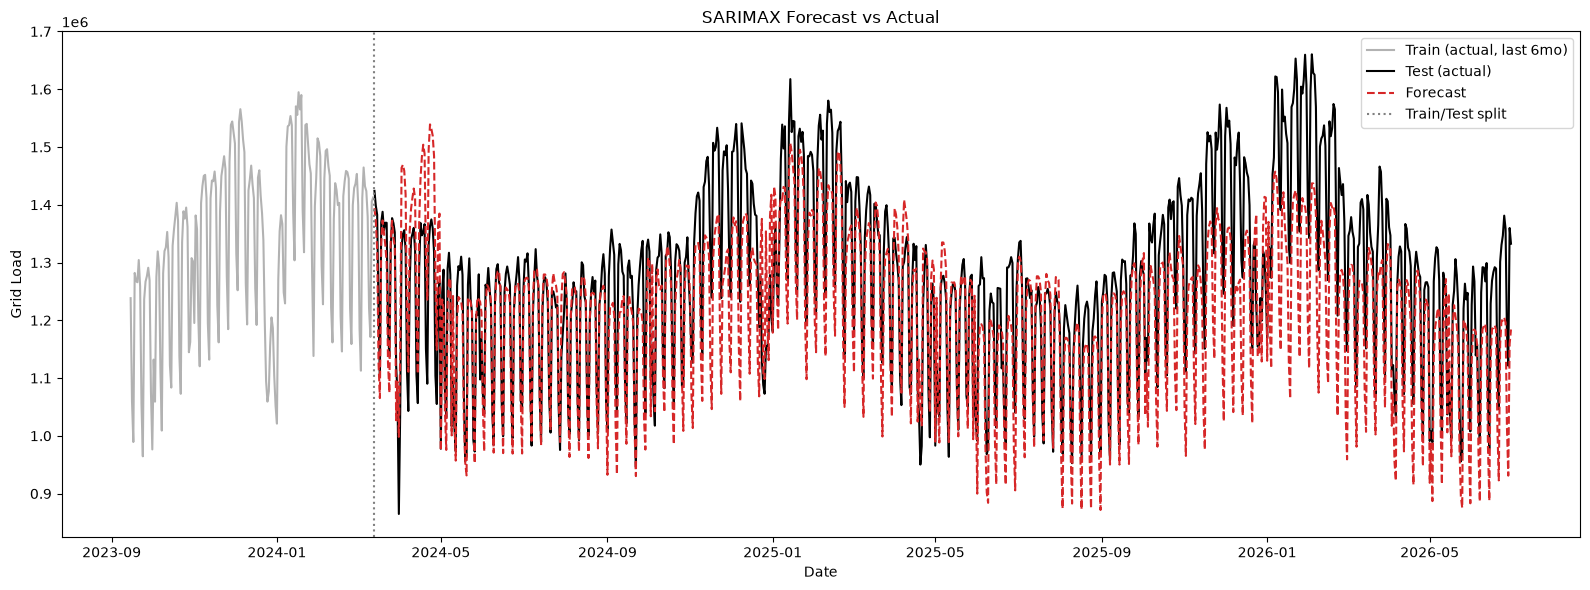

In [32]:
train_dates = merged_dates.iloc[:-test_size]

plt.figure(figsize=(16, 6))
plt.plot(train_dates.iloc[-180:], y_train.values[-180:], label="Train (actual, last 6mo)", color="grey", alpha=0.6)
plt.plot(test_dates, y_test.values, label="Test (actual)", color="black", linewidth=1.5)
plt.plot(test_dates, forecast.values, label="Forecast", color="tab:red", linestyle="--", linewidth=1.5)
plt.axvline(test_dates.iloc[0], color="grey", linestyle=":", label="Train/Test split")
plt.xlabel("Date")
plt.ylabel("Grid Load")
plt.title("SARIMAX Forecast vs Actual")
plt.legend()
plt.tight_layout()
plt.show()

##### lets add a confidence intervall

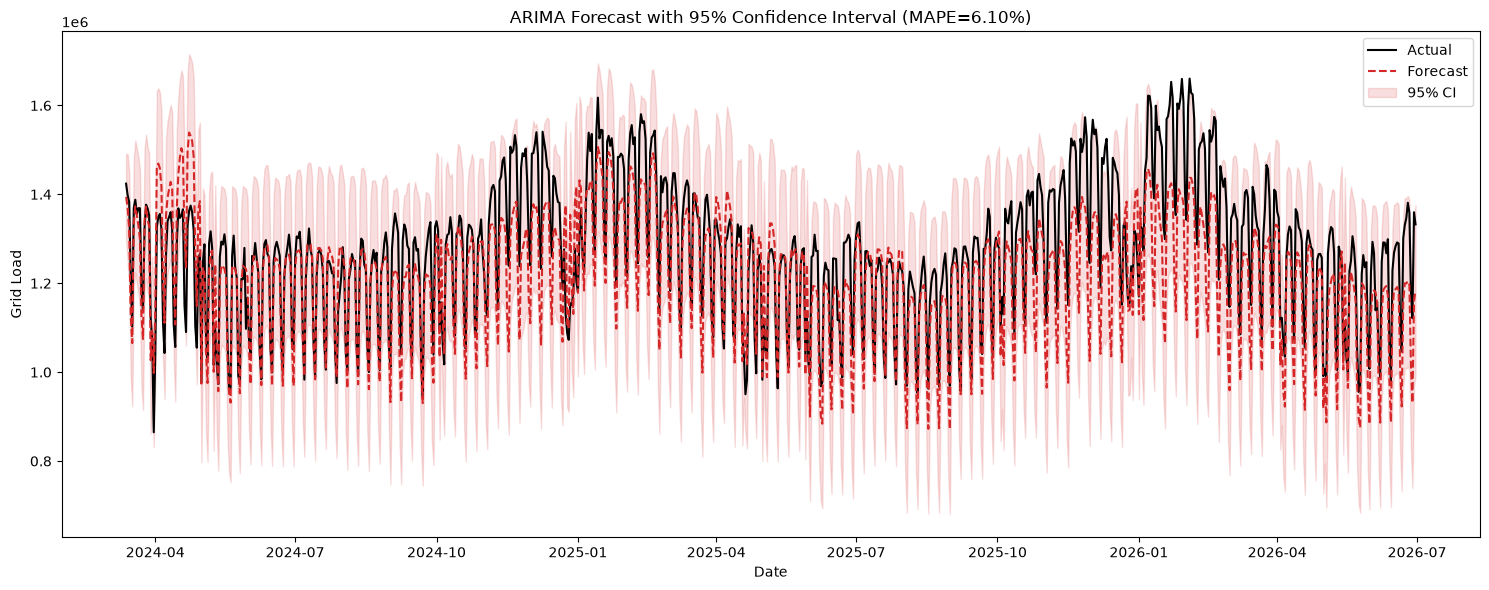

In [33]:
forecast_obj = fit.get_forecast(steps=test_size, exog=exog_test)
forecast_mean = forecast_obj.predicted_mean
conf_int = forecast_obj.conf_int(alpha=0.05)  # 95% confidence interval

plt.figure(figsize=(15, 6))
plt.plot(test_dates, y_test.values, label="Actual", color="black", linewidth=1.5)
plt.plot(test_dates, forecast_mean.values, label="Forecast", color="tab:red", linestyle="--", linewidth=1.5)
plt.fill_between(
    test_dates,
    conf_int.iloc[:, 0],
    conf_int.iloc[:, 1],
    color="tab:red", alpha=0.15, label="95% CI"
)
plt.xlabel("Date")
plt.ylabel("Grid Load")
plt.title(f"ARIMA Forecast with 95% Confidence Interval (MAPE={mape:.2%})")
plt.legend()
plt.tight_layout()
plt.show()

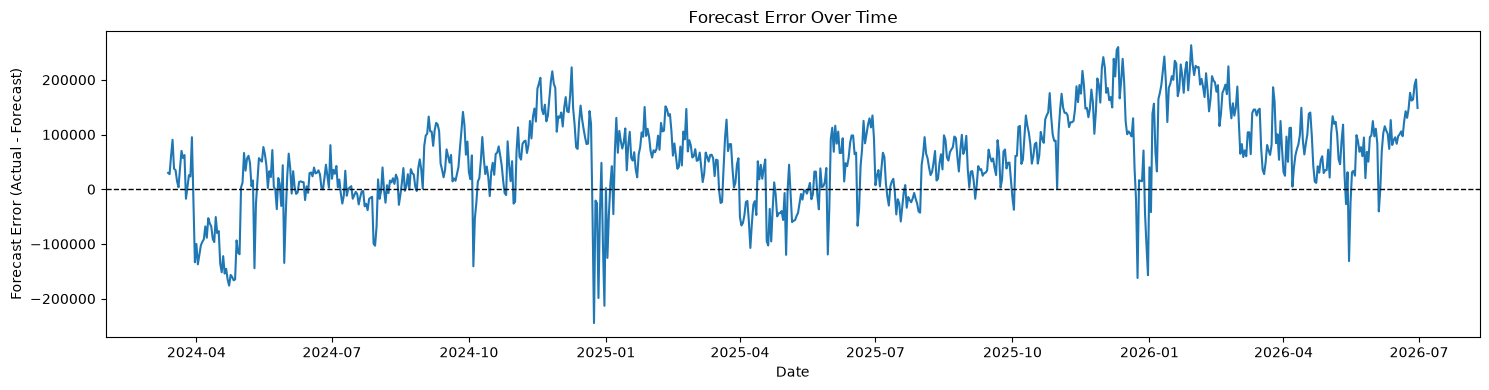

In [34]:
errors = y_test.values - forecast.values

plt.figure(figsize=(15, 4))
plt.plot(test_dates, errors, color="tab:blue")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Date")
plt.ylabel("Forecast Error (Actual - Forecast)")
plt.title("Forecast Error Over Time")
plt.tight_layout()
plt.show()

<div style="text-align:left;">
    <span style="color: red; font-size:14px; font-weight:bold;">
        A growing positive bias overtime, the model is still increasingly underpredicting as the horizon lengthens 
        The erros are too large around christmas time and well before the end of the year
        The model seems to follow much the path of production index and lean towards a down trend
    </span>
</div>

##### We will be adding an holiday period not only holiday date to deal with the low-activity around Christmas and New Year.
##### In order to deal with the Model follow towards the Production index drop we will be introducing an explicit linear time trend to address the MWh/day drift

In [35]:
merged["is_holiday_period"] = (
    ((merged["date"].dt.month == 12) & (merged["date"].dt.day >= 23)) |
    ((merged["date"].dt.month == 1) & (merged["date"].dt.day <= 2))
).astype(int)
merged["time_index"] = np.arange(len(merged))
final_vars = ["HDD_roll3", "CDD_roll3","CDD_roll7", "production_deseasonalized", "is_weekend", "is_holiday","is_holiday_period","time_index"]


X = merged[final_vars].dropna().astype(float)

vif_data = pd.DataFrame()
vif_data["variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data.sort_values("VIF", ascending=False))

                    variable       VIF
3  production_deseasonalized  5.050939
2                  CDD_roll7  4.877999
1                  CDD_roll3  4.626735
7                 time_index  3.346297
0                  HDD_roll3  2.379665
4                 is_weekend  1.401151
6          is_holiday_period  1.146701
5                 is_holiday  1.115745


In [37]:
dow_dummies = pd.get_dummies(merged["day_of_week"], prefix="dow", drop_first=True)

exog_vars = pd.concat([
    merged[["HDD_roll3", "CDD_roll3","CDD_roll7", "production_deseasonalized", "is_holiday","is_weekend","is_holiday_period","time_index"]],
    dow_dummies
], axis=1)

y = merged["Grid load [MWh]"]

valid = exog_vars.notna().all(axis=1) & y.notna()
y_valid = y[valid].reset_index(drop=True)
exog_valid = exog_vars[valid].astype(float).reset_index(drop=True)
merged_dates = merged.loc[valid, "date"].reset_index(drop=True)

test_size = 840

y_train, y_test = y_valid.iloc[:-test_size], y_valid.iloc[-test_size:]
exog_train, exog_test = exog_valid.iloc[:-test_size], exog_valid.iloc[-test_size:]

from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    y_train,
    exog=exog_train,
    order=(3,0,2),
    seasonal_order=(1,0,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
)
fit = model.fit(disp=False)
print(fit.summary())

/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                                      SARIMAX Results                                      
Dep. Variable:                     Grid load [MWh]   No. Observations:                 3353
Model:             SARIMAX(3, 0, 2)x(1, 0, [1], 7)   Log Likelihood              -40355.727
Date:                             Mon, 20 Jul 2026   AIC                          80755.454
Time:                                     16:07:16   BIC                          80889.976
Sample:                                          0   HQIC                         80803.575
                                            - 3353                                         
Covariance Type:                               opg                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
HDD_roll3                  1.532e+04    627.210     24.421      0.000    1.4

In [38]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

forecast = fit.forecast(steps=test_size, exog=exog_test)
mape = mean_absolute_percentage_error(y_test, forecast)
rmse = np.sqrt(mean_squared_error(y_test, forecast))
print(f"MAPE: {mape:.2%}, RMSE: {rmse:.2f}")

MAPE: 4.55%, RMSE: 75103.04


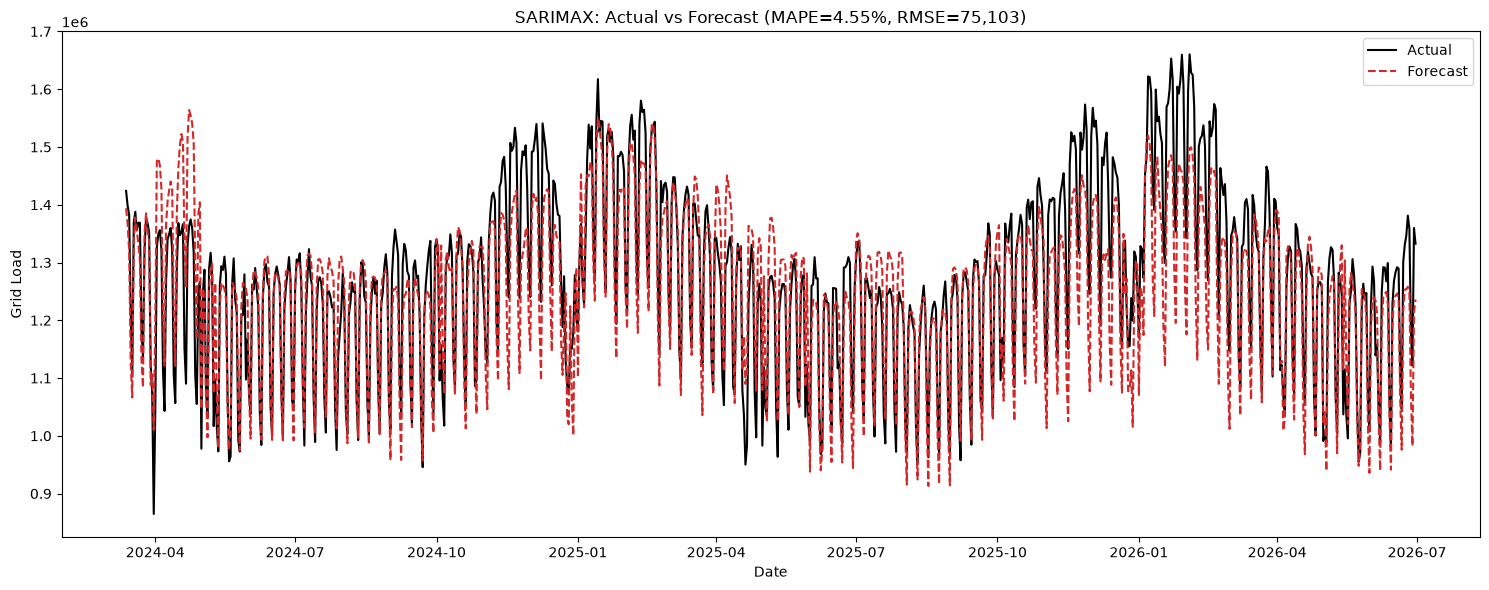

In [39]:
test_dates = merged_dates.iloc[-test_size:]

plt.figure(figsize=(15, 6))
plt.plot(test_dates, y_test.values, label="Actual", color="black", linewidth=1.5)
plt.plot(test_dates, forecast.values, label="Forecast", color="tab:red", linestyle="--", linewidth=1.5)
plt.xlabel("Date")
plt.ylabel("Grid Load")
plt.title(f"SARIMAX: Actual vs Forecast (MAPE={mape:.2%}, RMSE={rmse:,.0f})")
plt.legend()
plt.tight_layout()
plt.show()

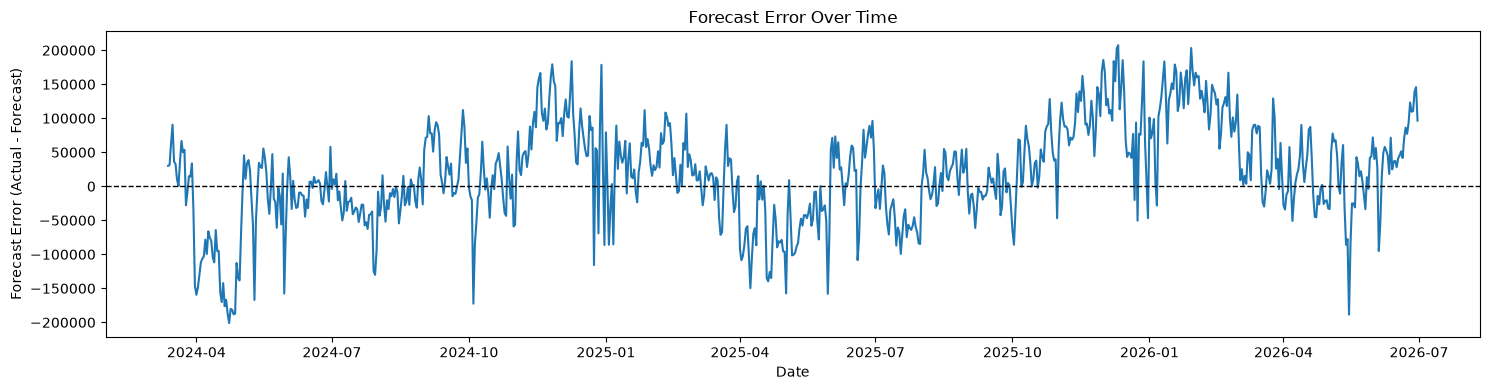

In [40]:
errors = y_test.values - forecast.values

plt.figure(figsize=(15, 4))
plt.plot(test_dates, errors, color="tab:blue")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Date")
plt.ylabel("Forecast Error (Actual - Forecast)")
plt.title("Forecast Error Over Time")
plt.tight_layout()
plt.show()

In [41]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from scipy import stats

mape = mean_absolute_percentage_error(y_test, forecast)
rmse = np.sqrt(mean_squared_error(y_test, forecast))
print(f"MAPE: {mape:.2%}, RMSE: {rmse:,.0f}")
errors = y_test.values - forecast.values
x = np.arange(len(errors))
slope, intercept, r_value, p_value, std_err = stats.linregress(x, errors)
print(f"Error trend: {slope:.1f} MWh/day, p-value={p_value:.4f}")

MAPE: 4.55%, RMSE: 75,103
Error trend: 107.7 MWh/day, p-value=0.0000


<div style="text-align:left;">
    <span style="color: blue; font-size:14px; font-weight:bold;">
        Lets evaluate the mean residual
    </span>
</div>

In [42]:
from scipy.stats import ttest_1samp

t_stat, p = ttest_1samp(errors, 0)
print(f"Mean error = {errors.mean():,.0f}")
print(f"p-value = {p:.4f}")

Mean error = 19,101
p-value = 0.0000


In [44]:
daily_test_average = y_test.mean()
Mean_error = errors.mean()
Bias = Mean_error/ daily_test_average
print(f"Bias Percentage: {Bias:.2%}")

Bias Percentage: 1.50%


In [45]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, forecast)
print(f"R² = {r2:.4f}")

R² = 0.7675


In [46]:
nrmse = rmse / daily_test_average

print(f"NRMSE = {nrmse:.2%}")

NRMSE = 5.90%


In [52]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Excl. weather sensitivity & Prod index(LSTM)", "New incl All (ARIMA)"],
    "MAPE (%)": [9.4, 4.55],
    "RMSE": [144908, 75103],
    "NRMSE (%)": ["NaN", 5.9],
    "Bias (%)": ["NaN", 1.5],
    "R²": [0.69, 0.77]
})

comparison

,Model,MAPE (%),RMSE,NRMSE (%),Bias (%),R²
0,Excl. weather sensitivity & Prod index(LSTM),9.40,144908,NaN,NaN,0.69
1,New incl All (ARIMA),4.55,75103,5.9,1.5,0.77


##### The model explains 76% of the variance in daily grid load over an 18-month out-of-sample test period, achieving a mean absolute percentage error of 4.55% and a near-zero bias (1.5%). The relatively moderate R², despite strong percentage accuracy, reflects the high day-to-day variance inherent in daily grid load data (weekly cycles, weather variability) rather than a shortfall in the model's absolute forecasting accuracy."

In [54]:
effects = pd.DataFrame({
    "Variable": [
        "Holiday",
        "Weekend",
        "HDD_roll3",
        "CDD_roll3",
        "Production"
    ],
    "Coefficient": [
        -286300,
        -149500,
        15150,
        10620,
        5046
    ],
    "Interpretation": [
        "Demand decreases by 286,300 MWh on holidays",
        "Demand decreases by 149,500 MWh on weekends",
        "Each additional HDD increases demand by 15,150 MWh",
        "Each additional CDD increases demand by 10,620 MWh",
        "Each production unit increases demand by 5,046 MWh"
    ]
})

effects

,Variable,Coefficient,Interpretation
0,Holiday,-286300,"Demand decreases by 286,300 MWh on holidays"
1,Weekend,-149500,"Demand decreases by 149,500 MWh on weekends"
2,HDD_roll3,15150,"Each additional HDD increases demand by 15,150..."
3,CDD_roll3,10620,"Each additional CDD increases demand by 10,620..."
4,Production,5046,"Each production unit increases demand by 5,046..."
